# Árvore de Decisão — smotenc

Mesmas features, recorte temporal, Optuna (50 trials), TimeSeriesSplit (5 folds), seleção por PR-AUC e limiar por F1 do XGBoost. O balanceamento é aplicado **somente ao treino de cada fold**, nunca à validação ou ao teste.


In [1]:
# Celula 1: prepara o ambiente de trabalho para toda a analise.
# - pandas/numpy: manipulacao de dados
# - matplotlib: graficos
# - scikit-learn: validacao cruzada e metricas
# - xgboost: modelo de classificacao
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import TimeSeriesSplit
# from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    brier_score_loss,
    log_loss,
    ConfusionMatrixDisplay,
)

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report

# Instala automaticamente o optuna apenas se ele nao estiver disponivel.
try:
    import optuna
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna", "-q"])
    import optuna

# Instala automaticamente o optuna-dashboard apenas se ele nao estiver disponivel.
try:
    import optuna_dashboard
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna-dashboard", "-q"])
    import optuna_dashboard

# Mostra todas as colunas ao inspecionar DataFrames.
pd.set_option("display.max_columns", None)
print("Bibliotecas carregadas com sucesso.")
# Imbalanced-learn: reamostragem exclusivamente nos subconjuntos de treino.
try:
    from imblearn.under_sampling import RandomUnderSampler
    from imblearn.over_sampling import RandomOverSampler, SMOTE, SMOTENC
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "imbalanced-learn", "-q"])
    from imblearn.under_sampling import RandomUnderSampler
    from imblearn.over_sampling import RandomOverSampler, SMOTE, SMOTENC


c:\Users\Sofhia\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Bibliotecas carregadas com sucesso.


In [2]:
# Celula 2: leitura da base e preparo das variaveis de entrada.
csv_path = Path("../../tabela_final/table_orders_holidays_ecommerce_events.csv") # Path(r"C:\Users\otavi\OneDrive\Desktop\last-mile-tcc\backend\tabela_final\table_orders_holidays_ecommerce_events.csv")
df = pd.read_csv(csv_path)

target_col = "delivered_on_time"
if target_col not in df.columns:
    raise ValueError(f"A coluna alvo '{target_col}' nao foi encontrada no CSV.")

# =====================================================================
# 1. ENGENHARIA DO SLA (Prazo da Transportadora - LAST MILE)
# =====================================================================
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'], utc=True)
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'], utc=True)
df['order_delivered_carrier_date'] = pd.to_datetime(df['order_delivered_carrier_date'], utc=True)

# Quantos dias a transportadora tem para entregar apos pegar o pacote?
# df['prazo_transportadora_dias'] = (df['order_estimated_delivery_date'] - df['order_delivered_carrier_date']).dt.days

df['order_estimated_delivery_date'] = pd.to_datetime(
    df['order_estimated_delivery_date'], utc=True
)

df['order_delivered_carrier_date'] = pd.to_datetime(
    df['order_delivered_carrier_date'], utc=True
)

# Mesmo critério do PySpark: diferença entre datas
df['prazo_transportadora_dias'] = (
    df['order_estimated_delivery_date'].dt.normalize() -
    df['order_delivered_carrier_date'].dt.normalize()
).dt.days

print(
    "Pedidos já atrasados:",
    (df['prazo_transportadora_dias'] < 0).sum()
)



# Remover os casos onde a transportadora nunca pegou o pacote para evitar NaN no treino
df = df.dropna(subset=['prazo_transportadora_dias']).copy()

# Extraindo o mes da compra (sazonalidade - Black Friday, Natal)
# df['purchase_month'] = df['order_purchase_timestamp'].dt.month
df['carrier_month'] = df['order_delivered_carrier_date'].dt.month

# =====================================================================
# 1b. FEATURES DE INTERAÇÃO (Adicionadas para aumentar o sinal)
# =====================================================================
df['prazo_por_km'] = df['prazo_transportadora_dias'] / (df['distance_km'] + 1)
df['frete_por_kg'] = df['freight_value'] / (df['product_weight_g'] / 1000 + 0.1)
df['densidade_produto'] = df['product_weight_g'] / (df['volume_cm3'] + 1)

# =====================================================================
# 2. ORDENAÇÃO CRONOLÓGICA (Baseada no momento da coleta)
# =====================================================================
df = df.sort_values('order_delivered_carrier_date').reset_index(drop=True)

# Divide temporalmente: treino anterior a julho de 2018; validação via TimeSeriesSplit no treino; teste a partir de julho de 2018.
# Treino: ate Junho de 2018 | Teste: Julho de 2018 em diante.
date_col = df['order_delivered_carrier_date'].copy()
split_date = pd.to_datetime("2018-07-01", utc=True)

leakage_candidates = [
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "shipping_delay_hours",
    "delivery_time_days",
    "review_score",
]
leakage_cols = [c for c in leakage_candidates if c in df.columns]

# Separa previsores e alvo.
feature_cols = [c for c in df.columns if c != target_col and c not in leakage_cols]
X = df[feature_cols].copy()
# Inverte o alvo: atraso = 1, no prazo = 0.
y = (~df[target_col].astype(bool)).astype(int).copy()

colunas_remover = [
    "order_purchase_timestamp",
    "order_approved_at",
    "interval_code_delivered_carrier", # variável n ajudou no modelo
    "interval_code_delivered_customer",
    "order_estimated_delivery_date", # Ja usamos
    "shipping_limit_date",
    "delivered_on_time",
    "review_score",
    
    # --- FEATURES REDUNDANTES / BAIXA INFLUENCIA REMOVIDAS ---
    "is_holiday_in_7_days",
    "is_holiday_in_14_days",
    "had_holiday_7_days_ago",
    "had_holiday_14_days_ago",
    "holiday_at_purchase",
    "is_weekend",

    # --- TESTE: Remocao de cidades e category_name ---
    "customer_city",
    "seller_city",
    "category_name",
    # "same_city",  # Descomente se tambem quiser retirar a flag de mesma cidade


]

X = X.drop(columns=colunas_remover, errors='ignore')

# Converte colunas categoricas em tipo 'category' para suporte nativo no XGBoost
# cat_cols = ["customer_city", "seller_city", "category_name"]
# for col in cat_cols:
#     X[col] = X[col].fillna("Unknown").astype("category")
cat_cols = []  # Sem variaveis categoricas para este teste

train_mask = date_col < split_date
test_mask = date_col >= split_date

X_train = X[train_mask].copy()
y_train = y[train_mask].copy()
X_test = X[test_mask].copy()
y_test = y[test_mask].copy()

# =====================================================================
# STANDARDSCALER: normaliza as features numéricas (incluindo as recém criadas)
# =====================================================================
# num_cols = [c for c in X_train.columns if c not in cat_cols]
# scaler = StandardScaler()
# X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
# X_test[num_cols] = scaler.transform(X_test[num_cols])
num_cols = list(X_train.columns)
scaler = None  # Arvores de decisao (XGBoost) nao necessitam de normalizacao

pos_count = int((y_train == 1).sum())
total_linhas = len(X)
qtd_treino = len(X_train)
qtd_teste = len(X_test)

print(f"Total de registros: Linhas: {X.shape[0]:,} | Colunas: {X.shape[1]}\n")
print(f"Treino (ate Jun/2018): {qtd_treino:,} ({qtd_treino/total_linhas:.2%})")
print(f" - Atrasos no Treino: {pos_count} ({(y_train == 1).mean():.2%} do treino)\n")
print(f"Teste (Jul/2018 em diante): {qtd_teste:,} ({qtd_teste/total_linhas:.2%})")
print(f" - Atrasos no Teste: {(y_test == 1).sum()} ({(y_test == 1).mean():.2%} do teste)\n")

X_test.head()

Pedidos já atrasados: 0
Total de registros: Linhas: 33,603 | Colunas: 23

Treino (ate Jun/2018): 28,603 (85.12%)
 - Atrasos no Treino: 1322 (4.62% do treino)

Teste (Jul/2018 em diante): 5,000 (14.88%)
 - Atrasos no Teste: 499 (9.98% do teste)



,holiday_at_carrier,days_since_last_holiday,days_until_next_holiday,ecommerce_event_at_carrier,days_since_last_ecommerce_event,days_until_next_ecommerce_event,is_ecommerce_event_in_7_days,is_ecommerce_event_in_14_days,had_ecommerce_event_7_days_ago,had_ecommerce_event_14_days_ago,purchase_hour,purchase_day_of_week,price,freight_value,product_weight_g,volume_cm3,distance_km,same_city,prazo_transportadora_dias,carrier_month,prazo_por_km,frete_por_kg,densidade_produto
28603,0,32,7,0,50,41,0,0,0,0,15,5,58.99,13.07,200,3960.0,65.936,0,17,7,0.253974,43.566667,0.050492
28604,0,32,7,0,50,41,0,0,0,0,20,5,24.99,13.76,2350,10648.0,411.255,0,17,7,0.041237,5.616327,0.220678
28605,0,32,7,0,50,41,0,0,0,0,10,6,119.90,13.50,459,3276.0,284.778,0,21,7,0.073484,24.150268,0.140067
28606,0,32,7,0,50,41,0,0,0,0,8,6,49.00,13.00,250,640.0,221.179,0,18,7,0.081016,37.142857,0.390016
28607,0,32,7,0,50,41,0,0,0,0,14,5,106.00,17.95,3305,35100.0,112.930,0,11,7,0.096551,5.271659,0.094157


In [3]:
# Celula 3: define funcoes e configuracoes da busca de hiperparametros.
# A avaliacao desta analise trata "atraso" como classe positiva (1).
def metricas_atraso(y_true, y_pred_atraso, y_proba_atraso):
    return {
        "accuracy_atraso": accuracy_score(y_true, y_pred_atraso),
        "precision_atraso": precision_score(y_true, y_pred_atraso, zero_division=0),
        "recall_atraso": recall_score(y_true, y_pred_atraso, zero_division=0),
        "f1_atraso": f1_score(y_true, y_pred_atraso, zero_division=0),
        "f2_atraso": fbeta_score(y_true, y_pred_atraso, beta=2, zero_division=0),
        "roc_auc_atraso": roc_auc_score(y_true, y_proba_atraso),
        "pr_auc_atraso": average_precision_score(y_true, y_proba_atraso),
        "balanced_accuracy_atraso": balanced_accuracy_score(y_true, y_pred_atraso),
        "mcc_atraso": matthews_corrcoef(y_true, y_pred_atraso),
        "brier_score_atraso": brier_score_loss(y_true, y_proba_atraso),
        "log_loss_atraso": log_loss(y_true, y_proba_atraso),
    }


def metricas_gerais(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Brier Score": brier_score_loss(y_true, y_proba),
        "Log Loss": log_loss(y_true, y_proba),
    }

# Configuracao do Optuna para busca de hiperparametros.
n_trials = 50
study_seed = 42
cv_tune = TimeSeriesSplit(n_splits=5)
threshold_grid_tune = np.arange(0.05, 0.81, 0.01)

# Vetor binario: 1 = atraso, 0 = nao atraso.
y_train_atraso = y_train.values

print("Preparacao da busca de hiperparametros concluida.")
# SMOTENC considera explicitamente quais features sao categoricas.
# As features binarias e codigos discretos sao detectados, sem tratar numeros continuos como categorias.
# Se nao houver categorias, usa-se SMOTE (SMOTENC exige ao menos uma categoria).
from pandas.api.types import is_bool_dtype, is_categorical_dtype, is_object_dtype


CATEGORICAS_EXPLICITAS = {
    "holiday_at_carrier",
    "ecommerce_event_at_carrier",
    "is_ecommerce_event_in_7_days",
    "is_ecommerce_event_in_14_days",
    "had_ecommerce_event_7_days_ago",
    "had_ecommerce_event_14_days_ago",
    "purchase_hour",
    "purchase_day_of_week",
    "same_city"
}


def identificar_categoricas(X_ref):
    categorias = []
    for coluna in X_ref.columns:
        serie = X_ref[coluna]
        if (coluna in CATEGORICAS_EXPLICITAS or is_bool_dtype(serie)
            or is_object_dtype(serie) or isinstance(serie.dtype, pd.CategoricalDtype)):
            categorias.append(coluna)
    return categorias

smotenc_cat_cols = identificar_categoricas(X_train)
print("Features categoricas para SMOTENC:", smotenc_cat_cols)

def aplicar_smotenc(X_parte, y_parte, seed=42):
    if X_parte.isna().any().any():
        raise ValueError("Existem valores ausentes: trate-os antes de aplicar SMOTENC.")
    if not all(pd.api.types.is_numeric_dtype(t) for t in X_parte.dtypes):
        raise ValueError("Existem features nao numericas: codifique-as antes de treinar a Árvore de Decisão.")
    n_min = int(y_parte.value_counts().min())
    if n_min < 2:
        raise ValueError("SMOTE/SMOTENC exige pelo menos 2 exemplos na classe minoritaria.")
    k = min(5, n_min - 1)
    if smotenc_cat_cols:
        sampler = SMOTENC(categorical_features=[X_parte.columns.get_loc(c) for c in smotenc_cat_cols],
                          sampling_strategy="auto", random_state=seed, k_neighbors=k)
    else:
        print("Aviso: nenhuma coluna categorica; utilizando SMOTE convencional.")
        sampler = SMOTE(sampling_strategy="auto", random_state=seed, k_neighbors=k)
    X_res, y_res = sampler.fit_resample(X_parte, y_parte)
    return pd.DataFrame(X_res, columns=X_parte.columns), pd.Series(y_res, name=y_parte.name)



def aplicar_balanceamento(X_parte, y_parte, seed=42):
    return aplicar_smotenc(X_parte, y_parte, seed=seed)


Preparacao da busca de hiperparametros concluida.
Features categoricas para SMOTENC: ['holiday_at_carrier', 'ecommerce_event_at_carrier', 'is_ecommerce_event_in_7_days', 'is_ecommerce_event_in_14_days', 'had_ecommerce_event_7_days_ago', 'had_ecommerce_event_14_days_ago', 'purchase_hour', 'purchase_day_of_week', 'same_city']


In [4]:
# Celula 4: busca de hiperparametros com Optuna + validacao cruzada temporal.
# Mesmo criterio do XGBoost: maximizar PR-AUC; threshold escolhido por F1,
# com desempate por Recall e depois Precision da classe atraso (1).
#
# Os hiperparametros abaixo sao proprios da Arvore de Decisao.
# Nao faria sentido copiar learning_rate, n_estimators, gamma etc. do XGBoost,
# pois eles nao existem em DecisionTreeClassifier.

optuna_db_path = Path("optuna_arvore_smotenc_temporal.db").resolve()
study_storage = f"sqlite:///{optuna_db_path.as_posix()}"
study_name = "arvore_de_decisao"

def objective(trial):
    params = {
        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy", "log_loss"]),
        "max_depth": trial.suggest_int("max_depth", 2, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 10, 200, step=10),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 5, 100, step=5),
        "max_features": trial.suggest_categorical("max_features", [None, "sqrt", "log2"]),
        "ccp_alpha": trial.suggest_float("ccp_alpha", 0.0, 0.02),
    }

    oof_proba_atraso = np.zeros(len(y_train), dtype=float)
    valid_mask = np.zeros(len(y_train), dtype=bool)

    for fold, (tr_idx, va_idx) in enumerate(cv_tune.split(X_train, y_train), start=1):
        X_tr, X_va = X_train.iloc[tr_idx], X_train.iloc[va_idx]
        y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]

        mdl = DecisionTreeClassifier(
            random_state=42,
            class_weight=None,
            **params,
        )
        X_fit, y_fit = aplicar_balanceamento(X_tr, y_tr, seed=42 + fold)
        mdl.fit(X_fit, y_fit)

        proba_atraso_va = mdl.predict_proba(X_va)[:, 1]
        oof_proba_atraso[va_idx] = proba_atraso_va
        valid_mask[va_idx] = True

    # TimeSeriesSplit nao usa o bloco inicial como validacao.
    # Calculamos as metricas apenas nos registros que realmente receberam predicao OOF.
    y_oof = y_train_atraso[valid_mask]
    proba_oof = oof_proba_atraso[valid_mask]
    pr_auc_i = average_precision_score(y_oof, proba_oof)

    best_thr_i = 0.50
    best_f1_i = -1.0
    best_recall_i = -1.0
    best_precision_i = -1.0

    for thr in threshold_grid_tune:
        pred_atraso = (proba_oof >= thr).astype(int)
        precision_i = precision_score(y_oof, pred_atraso, zero_division=0)
        recall_i = recall_score(y_oof, pred_atraso, zero_division=0)
        f1_i = f1_score(y_oof, pred_atraso, zero_division=0)

        if (f1_i > best_f1_i) or (
            np.isclose(f1_i, best_f1_i) and recall_i > best_recall_i
        ) or (
            np.isclose(f1_i, best_f1_i)
            and np.isclose(recall_i, best_recall_i)
            and precision_i > best_precision_i
        ):
            best_f1_i = float(f1_i)
            best_recall_i = float(recall_i)
            best_precision_i = float(precision_i)
            best_thr_i = float(thr)

    trial.set_user_attr("best_threshold", best_thr_i)
    trial.set_user_attr("cv_pr_auc_atraso", pr_auc_i)
    trial.set_user_attr("cv_f1_atraso", best_f1_i)
    trial.set_user_attr("cv_recall_atraso", best_recall_i)
    trial.set_user_attr("cv_precision_atraso", best_precision_i)
    return pr_auc_i

sampler = optuna.samplers.TPESampler(seed=study_seed)
study = optuna.create_study(
    direction="maximize",
    sampler=sampler,
    study_name=study_name,
    storage=study_storage,
    load_if_exists=True,
)
study.optimize(objective, n_trials=n_trials, show_progress_bar=False)

best_trial = study.best_trial
best_params_v2 = best_trial.params
best_threshold_v2 = float(best_trial.user_attrs["best_threshold"])

tuning_rows = []
for t in study.trials:
    if t.value is None:
        continue
    tuning_rows.append({
        "candidate": t.number + 1,
        "cv_pr_auc_atraso": t.user_attrs.get("cv_pr_auc_atraso", np.nan),
        "cv_f1_atraso": t.user_attrs.get("cv_f1_atraso", np.nan),
        "cv_recall_atraso": t.user_attrs.get("cv_recall_atraso", np.nan),
        "cv_precision_atraso": t.user_attrs.get("cv_precision_atraso", np.nan),
        "best_threshold": t.user_attrs.get("best_threshold", np.nan),
        "params": t.params,
    })

df_tuning = pd.DataFrame(tuning_rows).sort_values(
    ["cv_pr_auc_atraso", "cv_f1_atraso", "cv_recall_atraso", "cv_precision_atraso"],
    ascending=False
).reset_index(drop=True)

print(f"Trials avaliados: {len(df_tuning)}")
print("Top 8 configuracoes pela validacao cruzada (PR-AUC -> F1 -> Recall):")
display(df_tuning.head(8))
print("\nMelhores hiperparametros encontrados:")
for key, value in best_params_v2.items():
    print(f" - {key}: {value}")
print(f"Melhor limiar (Optuna): {best_threshold_v2:.2f}")
print(f"Study name: {study_name}")


[I 2026-10-14 21:58:28,074] A new study created in RDB with name: arvore_temporal_xgb_smotenc_v1
[I 2026-10-14 21:58:36,467] Trial 0 finished with value: 0.07595087520717689 and parameters: {'criterion': 'entropy', 'max_depth': 13, 'min_samples_split': 40, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'ccp_alpha': 0.01416145155592091}. Best is trial 0 with value: 0.07595087520717689.
[I 2026-10-14 21:58:44,106] Trial 1 finished with value: 0.07204435782054219 and parameters: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_split': 40, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'ccp_alpha': 0.005824582803960838}. Best is trial 0 with value: 0.07595087520717689.
[I 2026-10-14 21:58:51,702] Trial 2 finished with value: 0.08168330975309196 and parameters: {'criterion': 'gini', 'max_depth': 8, 'min_samples_split': 100, 'min_samples_leaf': 80, 'max_features': 'log2', 'ccp_alpha': 0.0009290082543999545}. Best is trial 2 with value: 0.08168330975309196.
[I 2026-10-14 21:58:59,214] 

Trials avaliados: 50
Top 8 configuracoes pela validacao cruzada (PR-AUC -> F1 -> Recall):


,candidate,cv_pr_auc_atraso,cv_f1_atraso,cv_recall_atraso,cv_precision_atraso,best_threshold,params
0,49,0.153641,0.219215,0.288000,0.176952,0.67,"{'criterion': 'log_loss', 'max_depth': 6, 'min..."
1,36,0.151185,0.212488,0.288889,0.168046,0.68,"{'criterion': 'log_loss', 'max_depth': 7, 'min..."
2,35,0.150092,0.215589,0.288889,0.171958,0.65,"{'criterion': 'log_loss', 'max_depth': 7, 'min..."
3,40,0.149483,0.212426,0.272000,0.174260,0.68,"{'criterion': 'log_loss', 'max_depth': 6, 'min..."
4,33,0.148548,0.222036,0.235556,0.209984,0.64,"{'criterion': 'log_loss', 'max_depth': 4, 'min..."
5,50,0.148063,0.227397,0.295111,0.184958,0.64,"{'criterion': 'log_loss', 'max_depth': 5, 'min..."
6,41,0.147161,0.222036,0.235556,0.209984,0.64,"{'criterion': 'log_loss', 'max_depth': 4, 'min..."
7,44,0.146579,0.206333,0.269333,0.167219,0.68,"{'criterion': 'log_loss', 'max_depth': 8, 'min..."



Melhores hiperparametros encontrados:
 - criterion: log_loss
 - max_depth: 6
 - min_samples_split: 180
 - min_samples_leaf: 10
 - max_features: None
 - ccp_alpha: 0.00036845806603686717
Melhor limiar (Optuna): 0.67
Study name: arvore_temporal_xgb_smotenc_v1


Metricas no teste (foco em atraso = classe 1):


,Teste
accuracy_atraso,0.5410
precision_atraso,0.1669
recall_atraso,0.9018
f1_atraso,0.2817
f2_atraso,0.4795
roc_auc_atraso,0.8547
pr_auc_atraso,0.5565
balanced_accuracy_atraso,0.7014
mcc_atraso,0.2422
brier_score_atraso,0.3483


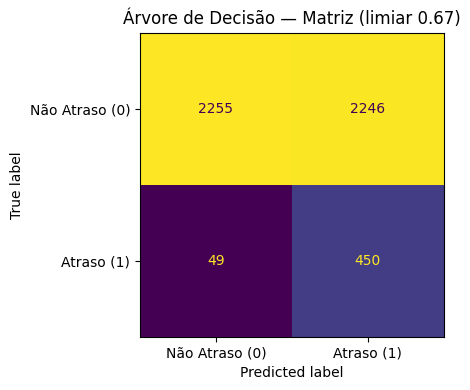


Classification report:
              precision    recall  f1-score   support

  Não Atraso       0.98      0.50      0.66      4501
      Atraso       0.17      0.90      0.28       499

    accuracy                           0.54      5000
   macro avg       0.57      0.70      0.47      5000
weighted avg       0.90      0.54      0.62      5000



In [5]:
# Celula 5: treino final + avaliacao no teste temporal.
model_v2 = DecisionTreeClassifier(
    random_state=42,
    class_weight=None,
    **best_params_v2,
)
X_fit_final, y_fit_final = aplicar_balanceamento(X_train, y_train, seed=42)
model_v2.fit(X_fit_final, y_fit_final)

y_proba_v2_train = model_v2.predict_proba(X_train)[:, 1]
y_proba_v2_test = model_v2.predict_proba(X_test)[:, 1]

y_pred_v2_train = (y_proba_v2_train >= best_threshold_v2).astype(int)
y_pred_v2_test = (y_proba_v2_test >= best_threshold_v2).astype(int)

res_v2_train = metricas_atraso(y_train, y_pred_v2_train, y_proba_v2_train)
res_v2_test = metricas_atraso(y_test, y_pred_v2_test, y_proba_v2_test)
metricas_treino_v2 = metricas_gerais(y_train, y_pred_v2_train, y_proba_v2_train)
metricas_teste_v2 = metricas_gerais(y_test, y_pred_v2_test, y_proba_v2_test)

print("Metricas no teste (foco em atraso = classe 1):")
display(pd.DataFrame(pd.Series(res_v2_test, name="Teste")).round(4))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_v2_test, ax=ax, colorbar=False,
    display_labels=["Não Atraso (0)", "Atraso (1)"]
)
ax.set_title(f"Árvore de Decisão — Matriz (limiar {best_threshold_v2:.2f})")
plt.tight_layout()
plt.show()

print("\nClassification report:")
print(classification_report(y_test, y_pred_v2_test, target_names=["Não Atraso", "Atraso"], zero_division=0))


In [6]:
# Celula 6: tabela de metricas equivalente a do XGBoost.
print("=" * 120)
print("METRICAS DE ATRASO (CLASSE 1)")
print("=" * 120)
print("\nTREINO")
display(pd.DataFrame(pd.Series(res_v2_train, name="Treino")).round(4))
print("\nTESTE")
display(pd.DataFrame(pd.Series(res_v2_test, name="Teste")).round(4))

comparacao_treino_teste = pd.DataFrame({
    "Metrica": ["Accuracy", "Precision atraso", "Recall atraso", "F1 atraso", "F2 atraso", "ROC-AUC", "PR-AUC"],
    "Treino": [
        metricas_treino_v2["Accuracy"], res_v2_train["precision_atraso"], res_v2_train["recall_atraso"],
        res_v2_train["f1_atraso"], res_v2_train["f2_atraso"], res_v2_train["roc_auc_atraso"],
        res_v2_train["pr_auc_atraso"]
    ],
    "Teste": [
        metricas_teste_v2["Accuracy"], res_v2_test["precision_atraso"], res_v2_test["recall_atraso"],
        res_v2_test["f1_atraso"], res_v2_test["f2_atraso"], res_v2_test["roc_auc_atraso"],
        res_v2_test["pr_auc_atraso"]
    ],
})
comparacao_treino_teste["Gap (Treino-Teste)"] = comparacao_treino_teste["Treino"] - comparacao_treino_teste["Teste"]
print("\nCOMPARAÇÃO TREINO X TESTE — útil para diagnosticar overfitting")
display(comparacao_treino_teste.round(4))


METRICAS DE ATRASO (CLASSE 1)

TREINO


,Treino
accuracy_atraso,0.8180
precision_atraso,0.1161
recall_atraso,0.4440
f1_atraso,0.1840
f2_atraso,0.2837
roc_auc_atraso,0.7330
pr_auc_atraso,0.2095
balanced_accuracy_atraso,0.6401
mcc_atraso,0.1542
brier_score_atraso,0.1768



TESTE


,Teste
accuracy_atraso,0.5410
precision_atraso,0.1669
recall_atraso,0.9018
f1_atraso,0.2817
f2_atraso,0.4795
roc_auc_atraso,0.8547
pr_auc_atraso,0.5565
balanced_accuracy_atraso,0.7014
mcc_atraso,0.2422
brier_score_atraso,0.3483



COMPARAÇÃO TREINO X TESTE — útil para diagnosticar overfitting


,Metrica,Treino,Teste,Gap (Treino-Teste)
0,Accuracy,0.8180,0.5410,0.2770
1,Precision atraso,0.1161,0.1669,-0.0509
2,Recall atraso,0.4440,0.9018,-0.4578
3,F1 atraso,0.1840,0.2817,-0.0977
4,F2 atraso,0.2837,0.4795,-0.1959
5,ROC-AUC,0.7330,0.8547,-0.1217
6,PR-AUC,0.2095,0.5565,-0.3470


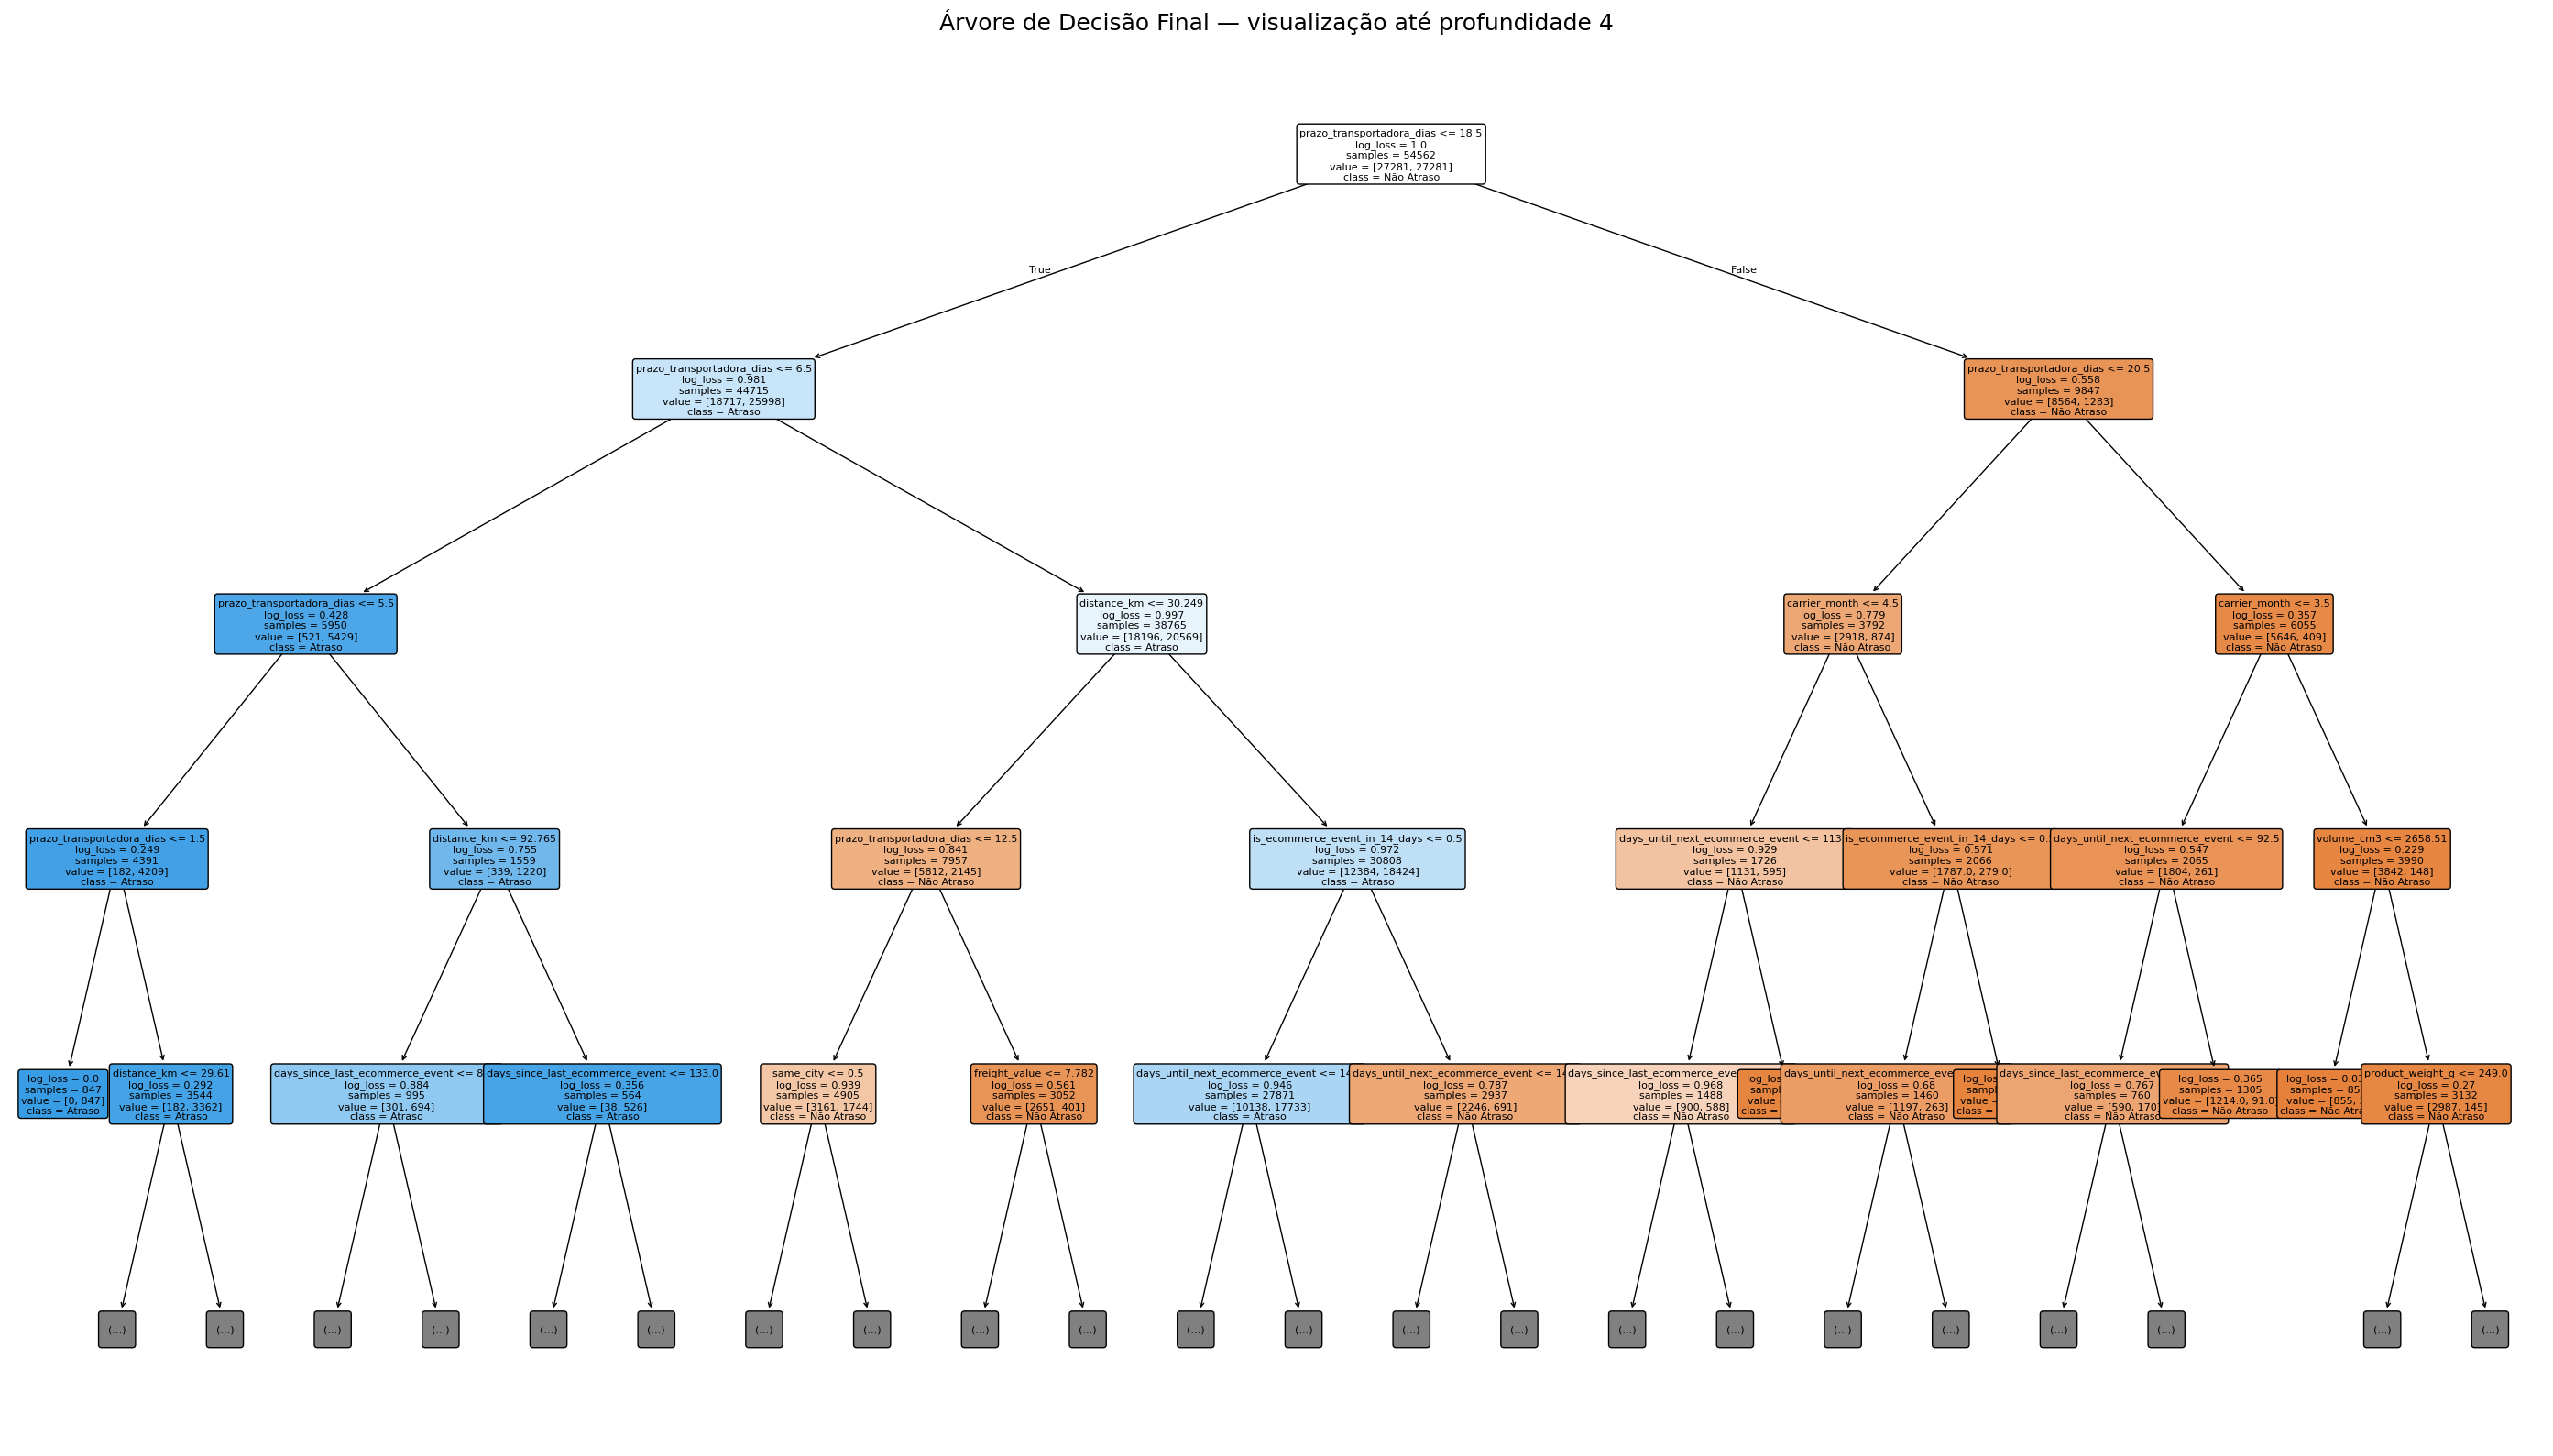

Profundidade completa: 6
Quantidade de folhas: 43
Quantidade total de nós: 85
Número de features disponíveis: 23

INSIGHT:
- Uma árvore muito profunda e com muitas folhas pode memorizar padrões do treino.
- Compare a complexidade acima com os gaps treino-teste da célula anterior.
- A visualização foi limitada a 4 níveis apenas para permitir interpretação das regras principais.


In [7]:
# Celula 7: INSIGHT ESPECIFICO DA ARVORE — estrutura, complexidade e regras.
plt.figure(figsize=(28, 16))
plot_tree(
    model_v2,
    feature_names=X_train.columns.tolist(),
    class_names=["Não Atraso", "Atraso"],
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=4
)
plt.title("Árvore de Decisão Final — visualização até profundidade 4", fontsize=18)
plt.tight_layout()
plt.show()

print("Profundidade completa:", model_v2.get_depth())
print("Quantidade de folhas:", model_v2.get_n_leaves())
print("Quantidade total de nós:", model_v2.tree_.node_count)
print("Número de features disponíveis:", model_v2.n_features_in_)

print("\nINSIGHT:")
print("- Uma árvore muito profunda e com muitas folhas pode memorizar padrões do treino.")
print("- Compare a complexidade acima com os gaps treino-teste da célula anterior.")
print("- A visualização foi limitada a 4 níveis apenas para permitir interpretação das regras principais.")


=== Importância das features — Árvore de Decisão ===


,feature,importance,importance_pct
0,prazo_transportadora_dias,0.5594,55.9404
1,distance_km,0.1264,12.6393
2,days_until_next_ecommerce_event,0.1238,12.3776
3,is_ecommerce_event_in_14_days,0.0865,8.6510
4,carrier_month,0.0197,1.9711
5,days_since_last_ecommerce_event,0.0175,1.7525
6,same_city,0.0163,1.6284
7,freight_value,0.0091,0.9117
8,prazo_por_km,0.0090,0.8958
9,had_ecommerce_event_14_days_ago,0.0076,0.7562


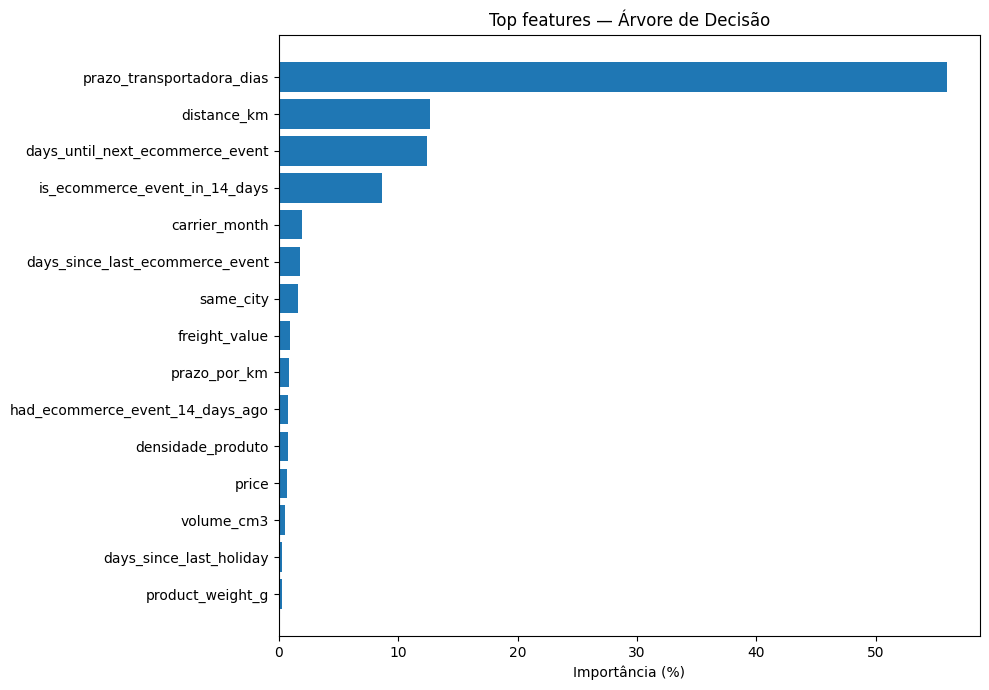


INSIGHTS:
- As primeiras posições mostram quais variáveis mais contribuíram para as divisões da árvore.
- Importância igual a zero indica que a feature não foi utilizada em nenhuma divisão do modelo final.
- Em árvores, a importância deve ser interpretada junto com as regras e com as métricas de generalização;
  uma feature muito dominante não significa, sozinha, relação causal com o atraso.


In [8]:
# Celula 8: INSIGHT ESPECIFICO DA ARVORE — importancia das features.
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": model_v2.feature_importances_,
}).sort_values("importance", ascending=False).reset_index(drop=True)

importance_df["importance_pct"] = importance_df["importance"] * 100

print("=== Importância das features — Árvore de Decisão ===")
display(importance_df.round(4))

top_n = min(15, len(importance_df))
plot_df = importance_df.head(top_n).sort_values("importance_pct")
plt.figure(figsize=(10, 7))
plt.barh(plot_df["feature"], plot_df["importance_pct"])
plt.xlabel("Importância (%)")
plt.title("Top features — Árvore de Decisão")
plt.tight_layout()
plt.show()

print("\nINSIGHTS:")
print("- As primeiras posições mostram quais variáveis mais contribuíram para as divisões da árvore.")
print("- Importância igual a zero indica que a feature não foi utilizada em nenhuma divisão do modelo final.")
print("- Em árvores, a importância deve ser interpretada junto com as regras e com as métricas de generalização;")
print("  uma feature muito dominante não significa, sozinha, relação causal com o atraso.")


In [9]:
# Celula 9: comparação do threshold otimizado contra 0.50.
pred_default = (y_proba_v2_test >= 0.50).astype(int)
pred_tuned = y_pred_v2_test

def resumo_threshold(y_true, pred, proba, nome):
    return {
        "Cenario": nome,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision atraso": precision_score(y_true, pred, zero_division=0),
        "Recall atraso": recall_score(y_true, pred, zero_division=0),
        "F1 atraso": f1_score(y_true, pred, zero_division=0),
        "F2 atraso": fbeta_score(y_true, pred, beta=2, zero_division=0),
        "PR-AUC": average_precision_score(y_true, proba),
    }

comparacao_threshold = pd.DataFrame([
    resumo_threshold(y_test, pred_default, y_proba_v2_test, "Threshold 0.50"),
    resumo_threshold(y_test, pred_tuned, y_proba_v2_test, f"Threshold otimizado {best_threshold_v2:.2f}"),
])
display(comparacao_threshold.round(4))

print("\nINSIGHT:")
print("- O threshold não altera a árvore treinada nem as probabilidades; ele altera a decisão final de classe.")
print("- Para o TCC, observe principalmente o efeito em Recall/F2 de atraso versus Precision.")


,Cenario,Accuracy,Precision atraso,Recall atraso,F1 atraso,F2 atraso,PR-AUC
0,Threshold 0.50,0.3864,0.1327,0.9299,0.2322,0.4224,0.5565
1,Threshold otimizado 0.67,0.5410,0.1669,0.9018,0.2817,0.4795,0.5565



INSIGHT:
- O threshold não altera a árvore treinada nem as probabilidades; ele altera a decisão final de classe.
- Para o TCC, observe principalmente o efeito em Recall/F2 de atraso versus Precision.


In [10]:
# Celula 10: resumo final com os principais insights da Arvore de Decisao.
print("=" * 100)
print("RESUMO FINAL — ARVORE DE DECISAO")
print("=" * 100)
print(f"Threshold escolhido na validação temporal: {best_threshold_v2:.2f}")
print(f"Profundidade: {model_v2.get_depth()} | Folhas: {model_v2.get_n_leaves()} | Nós: {model_v2.tree_.node_count}")
print("\nMelhores hiperparâmetros:")
for k, v in best_params_v2.items():
    print(f" - {k}: {v}")

print("\nMétricas de atraso no TESTE:")
for k in ["precision_atraso", "recall_atraso", "f1_atraso", "f2_atraso", "roc_auc_atraso", "pr_auc_atraso"]:
    print(f" - {k}: {res_v2_test[k]:.4f}")

print("\nTop 10 features:")
display(importance_df.head(10).round(4))

print("\nLEITURA PARA O TCC:")
print("1. Generalização: use os gaps treino-teste para verificar se a árvore está sofrendo overfitting.")
print("2. Classe minoritária: priorize PR-AUC, Recall, F1 e F2 de atraso, não apenas Accuracy.")
print("3. Interpretabilidade: profundidade, folhas e regras tornam a árvore mais explicável que modelos de ensemble.")
print("4. Features: discuta as variáveis mais importantes como sinais preditivos, sem tratá-las automaticamente como causas.")
print("5. Threshold: o limiar otimizado mostra o trade-off entre detectar mais atrasos e gerar falsos positivos.")


RESUMO FINAL — ARVORE DE DECISAO
Threshold escolhido na validação temporal: 0.67
Profundidade: 6 | Folhas: 43 | Nós: 85

Melhores hiperparâmetros:
 - criterion: log_loss
 - max_depth: 6
 - min_samples_split: 180
 - min_samples_leaf: 10
 - max_features: None
 - ccp_alpha: 0.00036845806603686717

Métricas de atraso no TESTE:
 - precision_atraso: 0.1669
 - recall_atraso: 0.9018
 - f1_atraso: 0.2817
 - f2_atraso: 0.4795
 - roc_auc_atraso: 0.8547
 - pr_auc_atraso: 0.5565

Top 10 features:


,feature,importance,importance_pct
0,prazo_transportadora_dias,0.5594,55.9404
1,distance_km,0.1264,12.6393
2,days_until_next_ecommerce_event,0.1238,12.3776
3,is_ecommerce_event_in_14_days,0.0865,8.6510
4,carrier_month,0.0197,1.9711
5,days_since_last_ecommerce_event,0.0175,1.7525
6,same_city,0.0163,1.6284
7,freight_value,0.0091,0.9117
8,prazo_por_km,0.0090,0.8958
9,had_ecommerce_event_14_days_ago,0.0076,0.7562



LEITURA PARA O TCC:
1. Generalização: use os gaps treino-teste para verificar se a árvore está sofrendo overfitting.
2. Classe minoritária: priorize PR-AUC, Recall, F1 e F2 de atraso, não apenas Accuracy.
3. Interpretabilidade: profundidade, folhas e regras tornam a árvore mais explicável que modelos de ensemble.
4. Features: discuta as variáveis mais importantes como sinais preditivos, sem tratá-las automaticamente como causas.
5. Threshold: o limiar otimizado mostra o trade-off entre detectar mais atrasos e gerar falsos positivos.


In [11]:
# Exportacao para deploy: MESMO CONTRATO do pickle do XGBoost.
# Executar somente depois de escolher parametros/limiar na validacao e avaliar no teste.
import pickle

raw_columns = [
    "purchase_date", "purchase_time", "carrier_datetime", "estimated_delivery_datetime",
    "price", "freight_value", "product_weight_g", "height_cm", "width_cm", "length_cm",
    "distance_km", "same_city", "customer_city", "seller_city", "category_name",
]

artefato_modelo = {
    "modelo": model_v2,
    "balanceamento": "smotenc",
    "hiperparametros": best_params_v2,
    "limiar": float(best_threshold_v2),
    "feature_names": list(X_train.columns),
    "num_cols": num_cols,
    "cat_cols": cat_cols,
    "scaler": scaler,
    "schema_version": 4,
    "inference_moment": "carrier_collection",
    "raw_columns": raw_columns,
    "ecommerce_events": [
        "mothers_day", "fathers_day", "children_day",
        "black_friday", "cyber_monday", "christmas",
    ],
}

nome_arquivo = "arvore_decisao_lastmile_smotenc_model.pkl"
with open(nome_arquivo, "wb") as arquivo:
    pickle.dump(artefato_modelo, arquivo, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Artefato salvo: {nome_arquivo}")
print(f"Features: {len(artefato_modelo['feature_names'])} | Limiar: {artefato_modelo['limiar']:.2f}")
print("Balanceamento: nenhum | Contrato de inferencia: igual ao XGBoost")


Artefato salvo: arvore_decisao_lastmile_smotenc_model.pkl
Features: 23 | Limiar: 0.67
Balanceamento: nenhum | Contrato de inferencia: igual ao XGBoost
